EXERCISE

You are a data scientist tasked with developing a predictive model for house prices. Your objective is to build a linear regression model that accurately predicts the sale price of houses based on various features.
- Split the dataset into a training set and a testing set to evaluate your model's performance (70:30).
- Develop a linear regression model using your selected features.
- Evaluate your model using appropriate metrics such as Mean Squared Error (MSE), Root Mean Squared Error (RMSE), or R-squared.
- Interpret the results and provide insights into the model's performance.

In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['figure.figsize'] = (6, 4)

In [5]:
house = pd.read_csv('housePrices/train.csv')

A. Exploratory Data Analysis (EDA)

In [6]:
house.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [7]:
print("Shape: ", house.shape)
print()
house.info()

Shape:  (1460, 81)

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18 

-> Explore target SalePrice

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Skewness:  1.8828757597682129
Skewness after log transformation:  0.12134661989685333


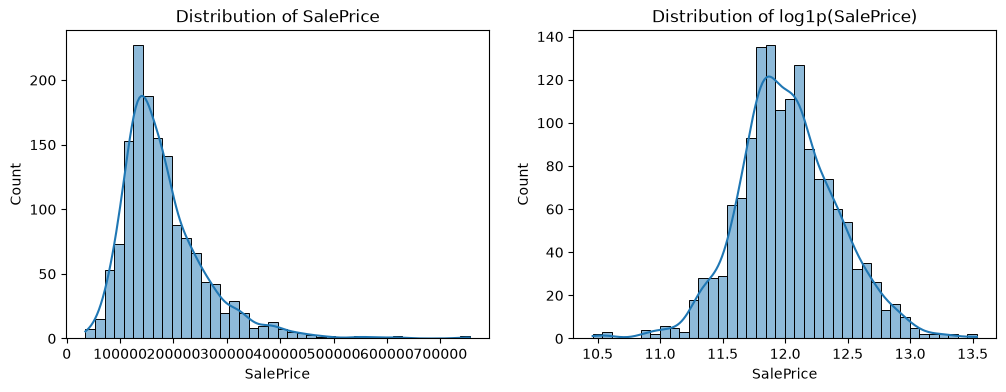

In [8]:
print(house['SalePrice'].describe())
print("Skewness: ", house['SalePrice'].skew())
print("Skewness after log transformation: ", np.log1p(house['SalePrice']).skew())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(house['SalePrice'], bins=40, kde=True, ax=ax[0])
ax[0].set_title('Distribution of SalePrice')
sns.histplot(np.log1p(house['SalePrice']), bins=40, kde=True, ax=ax[1])
ax[1].set_title('Distribution of log1p(SalePrice)')

# plt.tight_layout()
plt.show()


Analisa:
- Dataset yang terdiri dari 1460 rumah dan 81 kolom fitur. Harga rumah (SalePrice) rata-ratanya berada sekitar 181000 dollar (180921.195), median 163000 dolar, dan rumah termahal adalah 755000.
- Distribusi SalePrice miring ke kanan (skew 1.88) yang berarti kebanyakan rumah yang harganya menengah dan terdapat sedikit rumah yang sangat mahal. Setelah di-log distribusinya jauh lebih simetris dan terdistribusi dengan rata (skew 0.121). Ini nanti dipakai sebagai salah satu percobaan model.

-> Missing values

In [9]:
missing_values = house.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Columns with Missing Values:")
print(missing_values)

Columns with Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


-> Correlation between every feature

In [10]:
house.corr(numeric_only=True)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [11]:
corr = house.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).drop('SalePrice')
print(corr.head(10).round(3))

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64


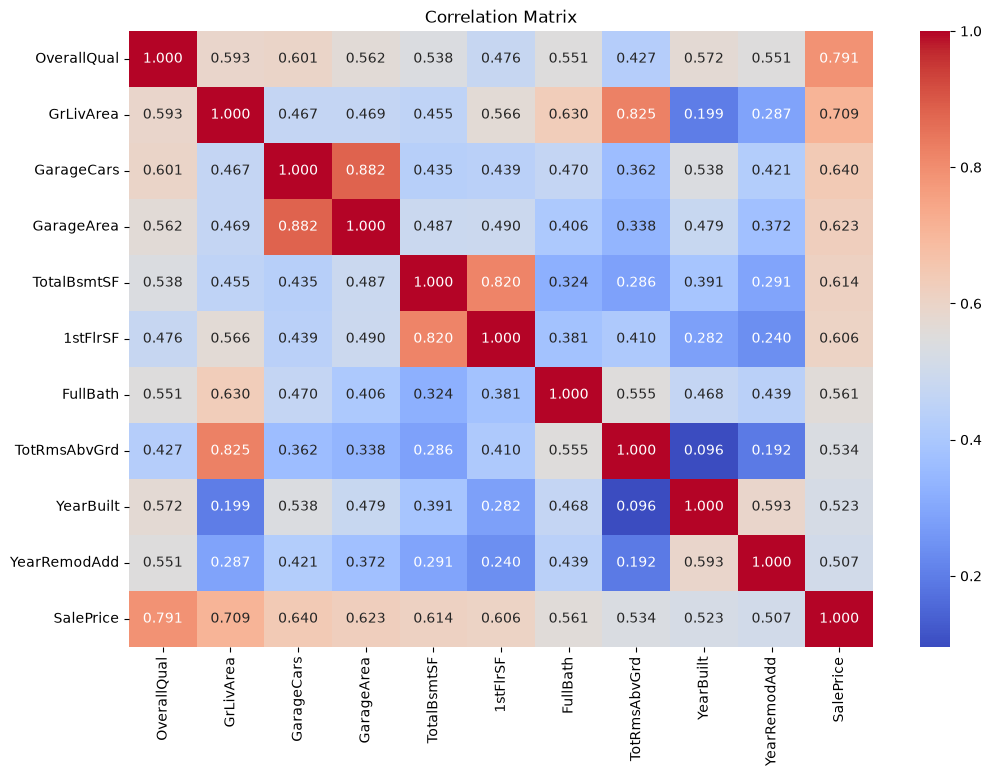

In [12]:
feature = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']
plt.figure(figsize=(12, 8))
sns.heatmap(house[feature + ['SalePrice']].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.3f')
plt.title("Correlation Matrix")

plt.show()


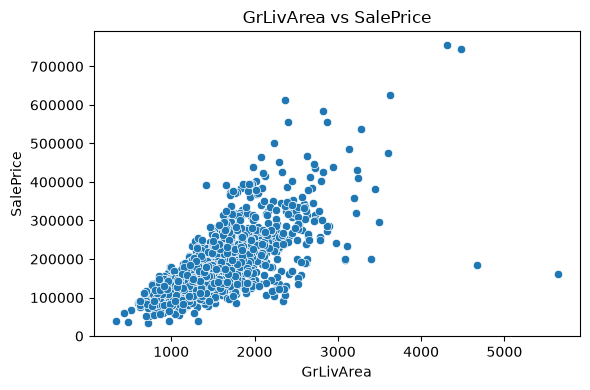

In [13]:
# fig, ax = plt.subplots(1,3, figsize=(15, 4))
# sns.scatterplot(data=house, x='GrLivArea', y='SalePrice', ax=ax[0])
# ax[0].set_title("GrLivArea vs SalePrice")
# sns.scatterplot(data=house, x='TotalBsmtSF', y='SalePrice', ax=ax[1])
# ax[1].set_title("TotalBsmtSF vs SalePrice")
# sns.boxplot(data=house, x='OverallQual', y='SalePrice', ax=ax[2])
# ax[2].set_title("OverallQual vs SalePrice")

fig, ax = plt.subplots()

sns.scatterplot(data=house, x='GrLivArea', y='SalePrice', ax=ax)
ax.set_title("GrLivArea vs SalePrice")

plt.tight_layout()
plt.show()

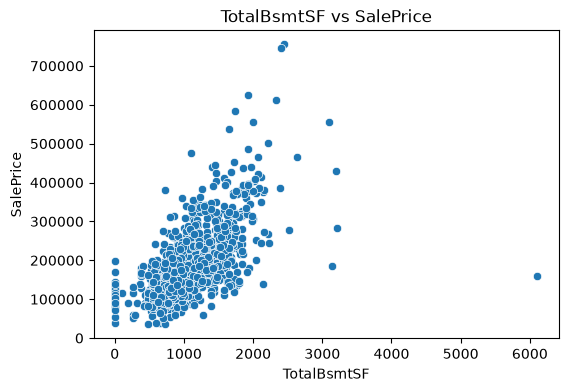

In [14]:
fig, ax = plt.subplots()

sns.scatterplot(data=house, x='TotalBsmtSF', y='SalePrice', ax=ax)
ax.set_title("TotalBsmtSF vs SalePrice")

plt.show()

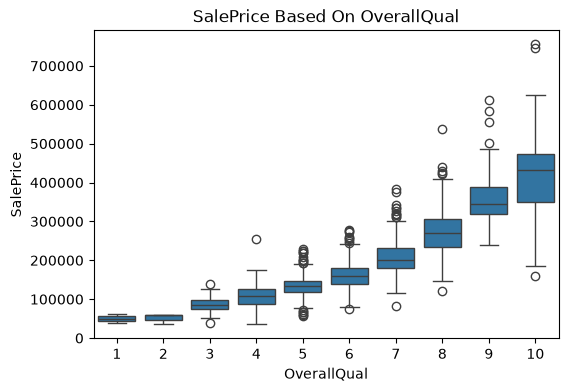

In [15]:
fig, ax = plt.subplots()

sns.boxplot(data=house, x='OverallQual', y='SalePrice', ax=ax)
ax.set_title("SalePrice Based On OverallQual")

plt.show()

Analisa:
- Fitur yang paling berkorelasi dengan SalePrice yaitu OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64), GarageArea (0.62), TotalBsmtSF (0.61), 1stFlrSF (0.61), dan FullBath (0.56).
- Ada fitur yang saling mirip: GarageCars dengan GarageArea, dan TotalBsmtSF dengan 1stFlrSF. Kalau dua-duanya dipakai, informasinya dobel dan koefisien regresi jadi susah ditafsirkan (multikolinearitas). Sehingga kami memutuskan untuk memilih salah satunya saja yaitu GarageCars dan TotalBsmtSF.
- Di scatter plot, GrLivArea dan TotalBsmtSF hubungannya kira-kira linear (makin luas makin mahal), dan OverallQual naik terus harganya tiap level. Jadi regresi linear cocok dipakai.
- Di GrLivArea ada beberapa titik yang aneh, yaitu rumah luas sekali (di atas 4000) tapi harganya murah.

-> Cek Outlier

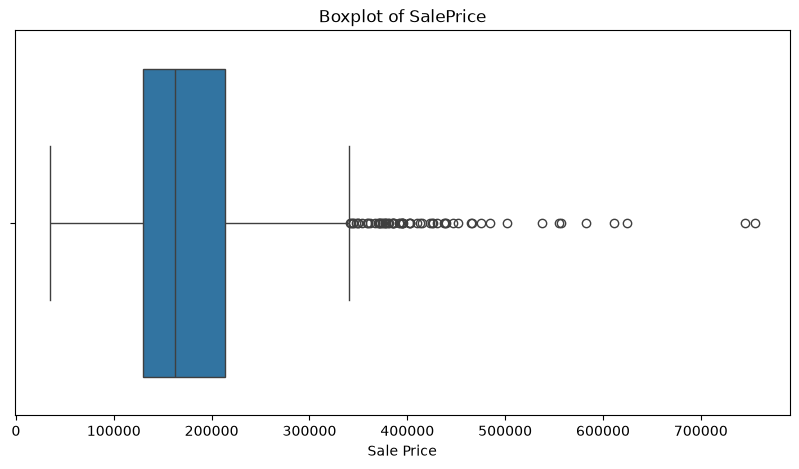

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=house['SalePrice'])
plt.title("Boxplot of SalePrice")
plt.xlabel("Sale Price")

plt.show()

In [17]:
house[house['GrLivArea']>4000][['Id','GrLivArea', 'SalePrice', 'OverallQual', 'TotRmsAbvGrd']].sort_values(by='GrLivArea', ascending=False)

,Id,GrLivArea,SalePrice,OverallQual,TotRmsAbvGrd
1298,1299,5642,160000,10,12
523,524,4676,184750,10,11
1182,1183,4476,745000,10,10
691,692,4316,755000,10,10


Analisa:
- Ada 4 rumah dengan GrLivArea di atas 4000. Rumah dengan Id 692 dan 1183 memiliki SalePrice di sekitar 750 ribu dolar, dengan overallquailty 10. Sedangkan rumah dengna id 524 dan 1299 dengan luas yang lebih dari dua rumah sebelumnya tapi harganya cuma 185 dan 160 ribu dolar padahal kualitasnya juga 10. Ini tidak sesuai pola dan bisa menarik garis regresi ke bawah, jadi kemungkinan dua rumah ini dihapus.

B. Data Preprocessing

-> Handling outlier and missing values

In [18]:
house = house[~((house['GrLivArea'] > 4000) & (house['SalePrice'] < 300000))]
print("Shape setelah outlier dihapus: ", house.shape)


fitur = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt', 'YearRemodAdd', 'Fireplaces']
print("Missing values pada fitur terpilih: ", house[fitur].isnull().sum().sum())

Shape setelah outlier dihapus:  (1458, 81)
Missing values pada fitur terpilih:  0


Analisa:
- 8 Fitur yang dipilih merupakan fitur-fitur numerik diantaranya OverallQual, GrLivArea, GarageCars, TotalBsmtSF, FullBath, YearBuilt, YearRemodAdd, dan Fireplaces. Delapan fitur ini dipilih karena korelasinya dengan SalePrice cukup tinggi dan saling tidak terlalu mirip.
- Tak hanya itu, semua fitur ini tidak ada yang missing value, jadi tidak perlu diisi atau dihapus barisnya.
- Serta semua fiturnya merupakan fitur numerik maka encoding tidak perlukan. Scaling juga tidak wajib untuk regresi linear (OLS). Pada soal ini kalau tidak di-scaling, koefisiennya lebih mudah dibaca dalam satuan asli (misal harga naik berapa dollar per tambahan 1 sqft).

-> Split data 70:30

In [19]:
x = house[fitur]
y = house['SalePrice']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

print("Train:", x_train.shape, " Test:", x_test.shape)

Train: (1020, 8)  Test: (438, 8)


C. Linear Regression Model

-> Model 1: Simple Linear Regression

In [20]:
model1 = LinearRegression()
model1.fit(x_train[['GrLivArea']], y_train)

print("Intercept (w0):", round(model1.intercept_, 2))
print("Koefisien GrLivArea (w1):", round(model1.coef_[0], 2))

Intercept (w0): 2228.35
Koefisien GrLivArea (w1): 118.75


In [21]:
# Fungsi untuk menghitung MSE, RMSE, MAE, dan R2
def hitung_metrik(y_asli, y_pred):
    mse = mean_squared_error(y_asli, y_pred)
    return {'MSE': round(mse), 'RMSE': round(np.sqrt(mse)), 'MAE': round(mean_absolute_error(y_asli, y_pred)), 'R2': round(r2_score(y_asli, y_pred), 3)}

hasil1 = pd.DataFrame({
    'Train': hitung_metrik(y_train, model1.predict(x_train[['GrLivArea']])),
    'Test': hitung_metrik(y_test, model1.predict(x_test[['GrLivArea']]))
})
hasil1

,Train,Test
MSE,2.960104e+09,2.786056e+09
RMSE,5.440700e+04,5.278300e+04
MAE,3.775600e+04,3.788400e+04
R2,5.470000e-01,5.210000e-01


-> Model 2: Multiple Linear Regression (8 fitur)

In [22]:
# Membuat dan melatih model dengan semua fitur
model2 = LinearRegression()
model2.fit(x_train, y_train)

print("Intercept (w0):", round(model2.intercept_, 2))

koef = pd.DataFrame({'Fitur': fitur, 'Koefisien': model2.coef_.round(2)}).sort_values(by='Koefisien', ascending=False)
koef

Intercept (w0): -1321405.85


,Fitur,Koefisien
0,OverallQual,15601.20
2,GarageCars,11201.28
7,Fireplaces,8169.68
6,YearRemodAdd,333.18
5,YearBuilt,300.92
1,GrLivArea,64.64
3,TotalBsmtSF,44.49
4,FullBath,-10075.46


In [23]:
# Menghitung metrik Model 2 pada data train dan test
pred_train2 = model2.predict(x_train)
pred_test2 = model2.predict(x_test)

hasil2 = pd.DataFrame({
    'Train': hitung_metrik(y_train, pred_train2),
    'Test': hitung_metrik(y_test, pred_test2)
})
hasil2

,Train,Test
MSE,1.196066e+09,9.952414e+08
RMSE,3.458400e+04,3.154700e+04
MAE,2.395300e+04,2.326000e+04
R2,8.170000e-01,8.290000e-01


In [24]:
# Mengecek hasil sklearn dengan rumus OLS dari materi: w = (X^T X)^-1 X^T y
x_bias = np.c_[np.ones(x_train.shape[0]), x_train.values]
w = np.linalg.inv(x_bias.T @ x_bias) @ x_bias.T @ y_train.values

print("Hasil OLS manual  :", w.round(2))
print()
print("Hasil sklearn     :", np.r_[model2.intercept_, model2.coef_].round(2))

Hasil OLS manual  : [-1.32140585e+06  1.56012000e+04  6.46400000e+01  1.12012800e+04
  4.44900000e+01 -1.00754600e+04  3.00920000e+02  3.33180000e+02
  8.16968000e+03]

Hasil sklearn     : [-1.32140585e+06  1.56012000e+04  6.46400000e+01  1.12012800e+04
  4.44900000e+01 -1.00754600e+04  3.00920000e+02  3.33180000e+02
  8.16968000e+03]


-> Visualisasi hasil prediksi model 2

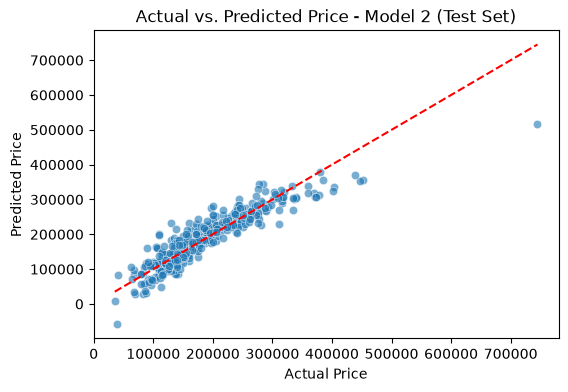

In [25]:
fig, ax = plt.subplots()

sns.scatterplot(x=y_test, y=pred_test2, alpha=0.6, ax=ax)

ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
ax.set_xlabel('Actual Price')
ax.set_ylabel('Predicted Price')
ax.set_title('Actual vs. Predicted Price - Model 2 (Test Set)')

plt.show()

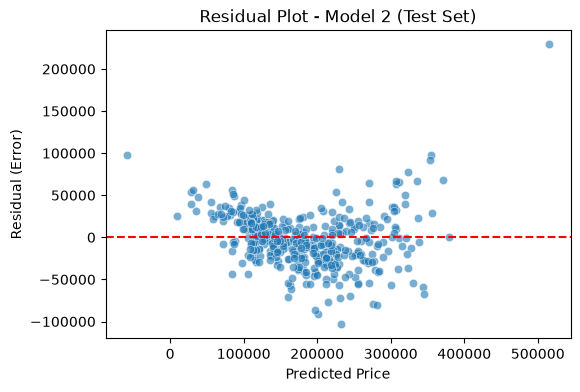

In [26]:
residual = y_test - pred_test2

fig, ax = plt.subplots()

sns.scatterplot(x=pred_test2, y=residual, alpha=0.6, ax=ax)

ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Predicted Price')
ax.set_ylabel('Residual (Error)')
ax.set_title('Residual Plot - Model 2 (Test Set)')

plt.show()

-> Model 3: Multiple Linear Regression dengan log(SalePrice)
Karena SalePrice miring ke kanan (lihat EDA), dicoba memprediksi log1p(SalePrice) lalu hasilnya dikembalikan ke harga asli dengan expm1.

In [27]:
# Model 3: Linear Regression dengan log transformasi pada target variable
model3 = LinearRegression()
model3.fit(x_train, np.log1p(y_train))

pred_train3 = np.expm1(model3.predict(x_train))
pred_test3 = np.expm1(model3.predict(x_test))

hasil3 = pd.DataFrame({
    'Train': hitung_metrik(y_train, pred_train3),
    'Test': hitung_metrik(y_test, pred_test3)
})
hasil3

,Train,Test
MSE,7.491962e+08,6.028939e+08
RMSE,2.737100e+04,2.455400e+04
MAE,1.891700e+04,1.879300e+04
R2,8.850000e-01,8.960000e-01


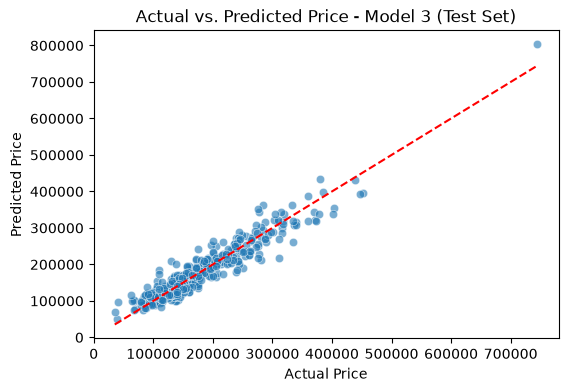

In [28]:
fig, ax = plt.subplots()

sns.scatterplot(x=y_test, y=pred_test3, alpha=0.6, ax=ax)

ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
ax.set_xlabel('Actual Price')
ax.set_ylabel('Predicted Price')
ax.set_title('Actual vs. Predicted Price - Model 3 (Test Set)')

plt.show()

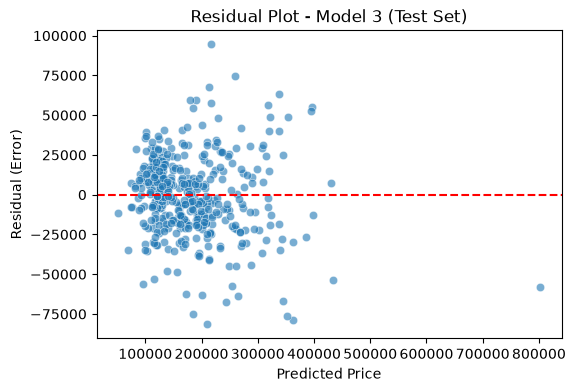

In [29]:
residual3 = y_test - pred_test3

fig, ax = plt.subplots()

sns.scatterplot(x=pred_test3, y=residual3, alpha=0.6, ax=ax)

ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Predicted Price')
ax.set_ylabel('Residual (Error)')
ax.set_title('Residual Plot - Model 3 (Test Set)')

plt.show()

D. Evaluasi dan Interpretasi

In [30]:
perbandingan = pd.DataFrame({
    'Model 1 (1 fitur)': hitung_metrik(y_test, model1.predict(x_test[['GrLivArea']])),
    'Model 2 (8 fitur)': hitung_metrik(y_test, pred_test2),
    'Model 3 (8 fitur + log)': hitung_metrik(y_test, pred_test3)
})
perbandingan

,Model 1 (1 fitur),Model 2 (8 fitur),Model 3 (8 fitur + log)
MSE,2.786056e+09,9.952414e+08,6.028939e+08
RMSE,5.278300e+04,3.154700e+04,2.455400e+04
MAE,3.788400e+04,2.326000e+04,1.879300e+04
R2,5.210000e-01,8.290000e-01,8.960000e-01


In [31]:
# Analisis Error Berdasarkan Harga Rumah Murah (80% terbawah) dan Mahal (20% teratas)
expensive_homes = y_test > y_test.quantile(0.8)

for name, pred in [('Model 2', pred_test2), ('Model 3', pred_test3)]:
    
    abs_err = (y_test - pred).abs()
    err_persen = abs_err / y_test * 100
    
    print(f"== {name} ==")
    print(f"  MAE affordable / luxury homes (USD)     : {round(abs_err[~expensive_homes].mean())} / {round(abs_err[expensive_homes].mean())}")
    print(f"  Mean error affordable / luxury homes (%) : {round(err_persen[~expensive_homes].mean(), 1)}% / {round(err_persen[expensive_homes].mean(), 1)}%")
    print(f"  Predictions below $50,000 (Count)       : {int((pred < 50000).sum())}")
    print("-" * 67)



== Model 2 ==
  MAE affordable / luxury homes (USD)     : 21443 / 30484
  Mean error affordable / luxury homes (%) : 16.6% / 9.6%
  Predictions below $50,000 (Count)       : 8
-------------------------------------------------------------------
== Model 3 ==
  MAE affordable / luxury homes (USD)     : 15991 / 29934
  Mean error affordable / luxury homes (%) : 12.2% / 10.1%
  Predictions below $50,000 (Count)       : 0
-------------------------------------------------------------------


In [32]:
# Menampilkan R2 untuk ketiga model
print("Model 1 -> train R2:", hasil1.loc['R2', 'Train'], " test R2:", hasil1.loc['R2', 'Test'])
print("Model 2 -> train R2:", hasil2.loc['R2', 'Train'], " test R2:", hasil2.loc['R2', 'Test'])
print("Model 3 -> train R2:", hasil3.loc['R2', 'Train'], " test R2:", hasil3.loc['R2', 'Test'])

Model 1 -> train R2: 0.547  test R2: 0.521
Model 2 -> train R2: 0.817  test R2: 0.829
Model 3 -> train R2: 0.885  test R2: 0.896


Analisa:
1. Performa Performa Model
Model 1 (Baseline-GrLivArea) yang hanya memakai satu fitur terbukti gagal karena cuma bisa menebak separuh variasi harga rumah. Performa melonjak drastis pada Model 2 (Multifeature-8 fitur) setelah kita memasukkan 8 fitur struktural utama. Namun, Model 3 (Logartima SalePrice) dengan skala logaritma adalah pemenang mutlak karena sukses menjelaskan 90 persen variasi harga pada data uji dan memangkas nilai kesalahan secara signifikan.
2. Alasan Utama Transformasi Log
Skala logaritma pada Model 3 terbukti menjadi penyelamat dalam menyeimbangkan performa. Pada Model 2, persentase kesalahan di kelompok rumah murah sangat bengkak (mencapai 17%) dan model sempat membuat 8 prediksi aneh di bawah $50k. Setelah diubah ke skala log pada Model 3, persentase error menjadi jauh lebih merata dan prediksi anomali yang terlalu rendah sukses dihilangkan.
3. Generalisasi dan Skala Error
Tidak ada indikasi overfitting sama sekali karena skor R2 pada data latihan dan data uji nilainya sangat mirip di ketiga model. Untuk Model 3, rata-rata kesalahan prediksi kita adalah $19k. Jika dibandingkan dengan rata-rata harga rumah yang berada di angka $181k, artinya tingkat melesetnya model ini hanya sekitar 10% saja.
4. Pr Rumah Mewah dan Faktor Lokasi
Meskipun performa Model 3 sudah bagus, nilai kesalahan dalam nominal dollar masih terlihat membengkak pada kelompok rumah mewah (MAE mencapai 30 ribu dollar). Hal ini menjadi petunjuk kuat bahwa model kita masih kehilangan variabel penting seperti faktor lokasi (Neighborhood) yang belum dimasukkan karena fiturnya saat ini masih berbentuk teks.
5. Arti Angka Koefisien Model 2
Jika fitur lain dianggap konstan, setiap kenaikan 1 tingkat kualitas rumah akan menaikkan harga sekitar 15.6 ribu dollar. Lalu, setiap tambahan luas 1 kaki persegi menyumbang 65 dollar, tambahan kapasitas 1 mobil di garasi bernilai 11 ribu dollar, dan keberadaan 1 perapian menambah nilai sekitar 8 ribu dollar.
6. Kasus Unik Kamar Mandi (Multikolinearitas)
Fitur jumlah kamar mandi (FullBath) memunculkan angka negatif sekitar minus 10 ribu dollar. Nilai negatif ini bukan berarti menambah kamar mandi akan menurunkan harga rumah, melainkan karena fiturnya punya korelasi kuat dengan luas bangunan (0.63). Nilai guna dari kamar mandi sebagian besar sudah diserap oleh metrik luas rumah, sehingga koefisiennya bergeser menjadi negatif untuk menyeimbangkan rumus matematika model. Kesimpulannya, nilai koefisien fitur individu dalam regresi linear tidak boleh dibaca secara harfiah begitu saja.

KESIMPULAN

Berdasarkan hasil pengujian, model Linear Regression dengan delapan fitur terpilih sudah cukup baik dalam memprediksi harga rumah. Model terbaik adalah Model 3 yang menggunakan transformasi log pada target 'SalePrice', dengan nilai R² testing sekitar 0,9. Artinya, model mampu menjelaskan sekitar 90% variasi harga rumah. Ke depannya, performa model masih bisa ditingkatkan dengan menambahkan fitur seperti Neighborhood atau mencoba algoritma regresi lainnya.


WEEK 5 REGULARIZATION : BASELINE, LASSO, RIDGE, ELASTIC NET

In [ ]:
# import warnings
# warnings.filterwarnings('ignore')   # sembunyikan ConvergenceWarning

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV, Ridge, lasso_path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


In [49]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
alpha_ridge = np.logspace(1, 5, 50)
alpha_lasso = np.logspace(0, 4, 50)
l1_grid = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
log_y_train = np.log1p(y_train)

In [50]:
daftar_model = {
    "Baseline" : LinearRegression(),
    'Ridge (L2)': RidgeCV(alphas=alpha_ridge, cv=kf),
    'Lasso (L1)': LassoCV(alphas=alpha_lasso, cv=kf, max_iter=100000, random_state=42),
    'Elastic Net': ElasticNetCV(l1_ratio=l1_grid, alphas=alpha_lasso, cv=kf, max_iter=100000, random_state=42),

}

hasil, model_reg = [], {}

for nama, est in daftar_model.items():
    pipe = make_pipeline(StandardScaler(), est).fit(x_train, log_y_train)
    model_reg[nama] = pipe
    m_tr = hitung_metrik(y_train, np.expm1(pipe.predict(x_train)))
    m_te = hitung_metrik(y_test, np.expm1(pipe.predict(x_test)))
    cv = cross_val_score(make_pipeline(StandardScaler(), est), x_train, log_y_train, cv=kf, scoring='r2')
    koef = pipe[-1].coef_
    hasil.append({
        'Model': nama,
        'alpha': round(float(getattr(est, 'alpha_', np.nan)), 4),
        'l1_ratio': getattr(est, 'l1_ratio_', np.nan),
        'Koef = 0': int((np.abs(koef) < 1e-8).sum()),
        'R2 train': m_tr['R2'], 'R2 test': m_te['R2'],
        'Gap (train-test)': round(m_tr['R2'] - m_te['R2'], 3),
        'RMSE test': m_te['RMSE'], 'MAE test': m_te['MAE'],
        'R2 CV (mean)': round(cv.mean(), 3), 'R2 CV (std)': round(cv.std(), 3),
    })
hasil_reg = pd.DataFrame(hasil).set_index('Model')
hasil_reg.T

Model,Baseline,Ridge (L2),Lasso (L1),Elastic Net
alpha,NaN,10.000,10000.000,1.000
l1_ratio,NaN,NaN,NaN,0.100
Koef = 0,0.000,0.000,8.000,0.000
R2 train,0.885,0.885,-0.032,0.568
R2 test,0.896,0.897,-0.023,0.608
Gap (train-test),-0.011,-0.012,-0.009,-0.040
RMSE test,24554.000,24507.000,77106.000,47738.000
MAE test,18793.000,18770.000,55024.000,31075.000
R2 CV (mean),0.865,0.865,-0.002,0.642
R2 CV (std),0.016,0.016,0.002,0.019


Analisa:
- Ridge (L2) dengan alpha = 10.0 memberikan hasil paling optimal dengan R^2 test 0.897, RMSE test $24,507, dan MAE test $18,770, sedikit mengungguli Baseline. Sebaliknya, Lasso dan Elastic Net mengalami penurunan performa yang tajam.
- Lasso mengalami underfitting ekstrem (semua koefisien nol): Nilai alpha = 10000.0 terlalu besar sehingga menekan seluruh 8 koefisien fitur menjadi 0. Akibatnya, model hanya menebak rata-rata target dengan R^2 test negatif (-0.023) dan RMSE test melonjak ke $77,106.
- Elastic Net mengalami underfitting cukup berat dimana dengan alpha = 1.0 dan l1_ratio = 0.1 (lebih condong ke penalti L2), tidak ada koefisien yang bernilai nol, tetapi kekuatan penaltinya masih terlalu tinggi. Hal ini menurunkan R^2 test menjadi 0.608 dengan RMSE test sebesar $47,738.
- Tidak terjadi overfitting pada semua model: Selisih R^2 train - R^2 test bernilai negatif untuk keempat model (-0.009 hingga -0.040), menandakan model tidak menghafal data latih. Skor test yang sedikit lebih tinggi daripada train disebabkan oleh variasi pembagian data (data splitting).
- Stabilitas data dan sensitivitas alpha: Skor Cross-Validation (R2 CV mean) yang identik antara Baseline dan Ridge (0.865, std 0.016) menunjukkan data sudah cukup stabil tanpa membutuhkan regularisasi agresif. Rentang alpha optimal untuk Lasso dan Elastic Net berada di bawah angka pengujian saat ini (ratusan untuk Lasso dan di bawah 1.0 untuk Elastic Net)

-> Koefisien tiap model (fitur sudah di-scale, target log1p, jadi koefisien bisa dibandingkan antar fitur)

,Baseline,Ridge (L2),Lasso (L1),Elastic Net
OverallQual,0.1022,0.1018,0.0,0.0670
GrLivArea,0.1392,0.1363,0.0,0.0544
GarageCars,0.0562,0.0566,0.0,0.0373
TotalBsmtSF,0.0742,0.0743,0.0,0.0350
FullBath,-0.0174,-0.0150,0.0,0.0094
YearBuilt,0.0610,0.0598,0.0,0.0191
YearRemodAdd,0.0510,0.0509,0.0,0.0164
Fireplaces,0.0441,0.0446,0.0,0.0079


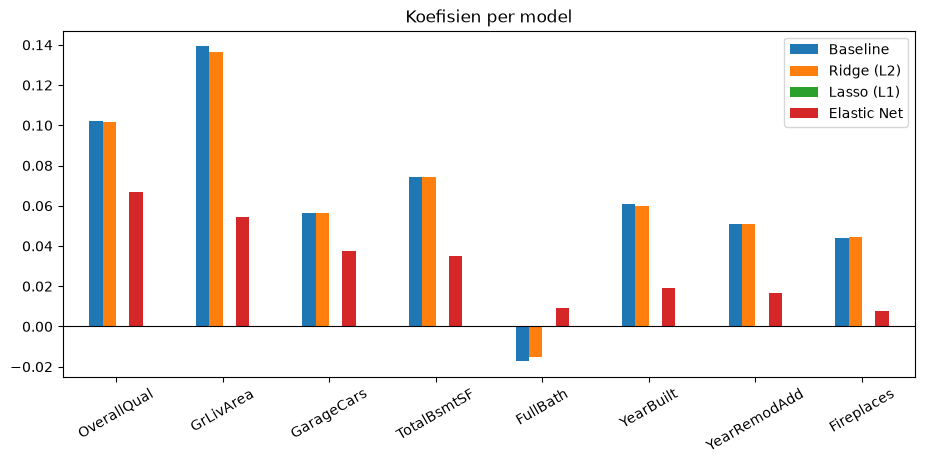

In [51]:
koef_tabel = pd.DataFrame({n: m[-1].coef_ for n, m in model_reg.items()}, index=fitur).round(4)
display(koef_tabel)

koef_tabel.plot(kind='bar', figsize=(11, 4.5), rot=30)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Koefisien per model')
plt.show()

-> R^2 train vs test

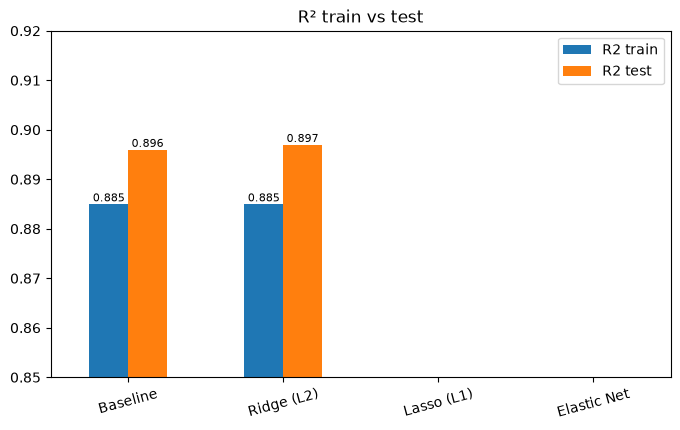

In [52]:
ax = hasil_reg[['R2 train', 'R2 test']].plot(kind='bar', figsize=(8, 4.5), rot=15)
ax.set_ylim(0.85, 0.92); ax.set_xlabel('')
ax.set_title('R² train vs test')
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.show()

-> Jalur koefisien (regularization path): apa yang terjadi kalau penaltinya dinaikkan?

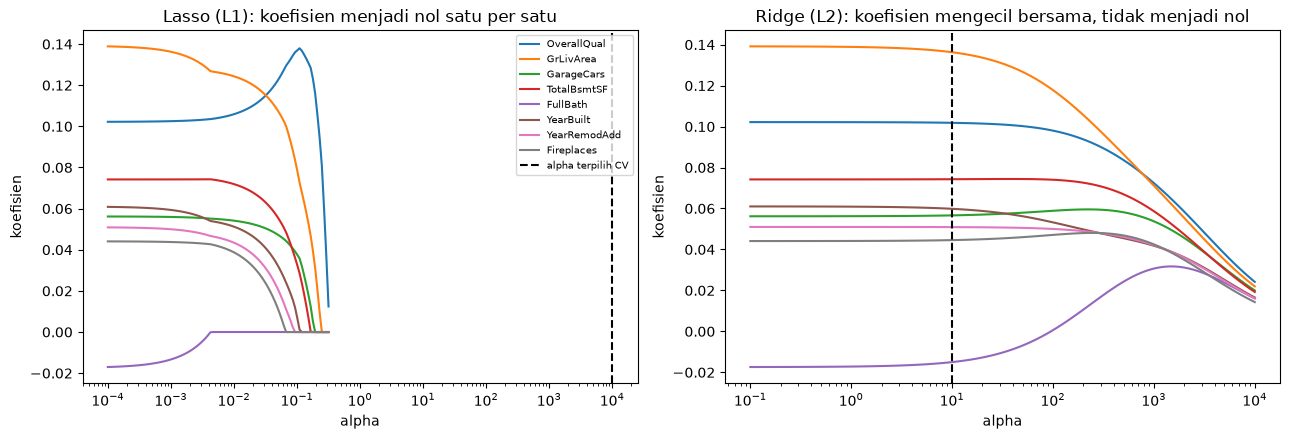

alpha tempat koefisien Lasso menjadi nol:
FullBath        0.0042
Fireplaces      0.0621
YearRemodAdd    0.0860
YearBuilt       0.1097
TotalBsmtSF     0.1649
GarageCars      0.1789
GrLivArea       0.2283
OverallQual     0.3162
dtype: float64


In [53]:
sc = StandardScaler().fit(x_train)
xs = sc.transform(x_train)

alphas_path, coefs_lasso, _ = lasso_path(xs, log_y_train, alphas=np.logspace(-4, -0.5, 100))
coefs_ridge = np.array([Ridge(alpha=a).fit(xs, log_y_train).coef_ for a in np.logspace(-1, 4, 100)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for j, f in enumerate(fitur):
    ax[0].plot(alphas_path, coefs_lasso[j], label=f)
ax[0].axvline(model_reg['Lasso (L1)'][-1].alpha_, color='black', linestyle='--', label='alpha terpilih CV')
ax[0].set_xscale('log'); ax[0].set_xlabel('alpha'); ax[0].set_ylabel('koefisien'); ax[0].set_title('Lasso (L1): koefisien menjadi nol satu per satu')
ax[0].legend(fontsize=7)

for j, f in enumerate(fitur):
    ax[1].plot(np.logspace(-1, 4, 100), coefs_ridge[:, j], label=f)
ax[1].axvline(model_reg['Ridge (L2)'][-1].alpha_, color='black', linestyle='--', label='alpha terpilih CV')
ax[1].set_xscale('log'); ax[1].set_xlabel('alpha'); ax[1].set_ylabel('koefisien'); ax[1].set_title('Ridge (L2): koefisien mengecil bersama, tidak menjadi nol')
plt.tight_layout()
plt.show()

# alpha tempat tiap koefisien Lasso menjadi nol (makin besar = makin penting)
urutan = {f: (alphas_path[np.abs(coefs_lasso[j]) > 1e-10].max() if (np.abs(coefs_lasso[j]) > 1e-10).any() else 0) for j, f in enumerate(fitur)}
print("alpha tempat koefisien Lasso menjadi nol:")
print(pd.Series(urutan).sort_values().round(4))

F. Ringkasan dan Kesimpulan

In [54]:
hasil_reg[['R2 train', 'R2 test', 'RMSE test', 'MAE test', 'R2 CV (mean)', 'Koef = 0']]

,R2 train,R2 test,RMSE test,MAE test,R2 CV (mean),Koef = 0
Model,,,,,,
Baseline,0.885,0.896,24554,18793,0.865,0
Ridge (L2),0.885,0.897,24507,18770,0.865,0
Lasso (L1),-0.032,-0.023,77106,55024,-0.002,8
Elastic Net,0.568,0.608,47738,31075,0.642,0


1.  Ridge (L2) sedikit mengungguli Baseline (OLS) dengan R^2 test 0.897 dan RMSE test $24,507. Sebaliknya, Lasso (L1) dan Elastic Net mengalami penurunan performa yang drastis akibat penalti yang terlalu besar.
2. Regularisasi agresif justru memicu underfitting karena model awal sudah seimbang. Skor train (0.885) dan skor test (0.896) pada Baseline dan Ridge sudah seimbang tanpa overfitting. Dengan hanya 8 fitur pilihan untuk 1.020 data, model sudah cukup ramping sehingga pemberian penalti berlebih pada Lasso dan Elastic Net justru merusak akurasi prediksi.
3. Dampak penalti terlihat jelas pada penurunan skor dan eliminasi fitur:
	- Ridge (L2): Menahan bobot fitur secara merata tanpa membuang satu pun fitur (Koef = 0 bernilai 0), sekaligus menjaga skor CV tetap stabil di 0.865.
	- Lasso (L1): Penalti yang terlalu tinggi membuang seluruh 8 fitur sekaligus menjadi nol, menyebabkan model mengalami underfitting ekstrem R^2 test -0.023 dan RMSE melonjak ke $77,106.
	- Elastic Net: Penalti gabungan L1 dan L2 tetap terlalu kuat untuk skala data ini meski tidak ada fitur yang menjadi nol, sehingga membuat R^2 test turun ke 0.608 dengan RMSE $47,738.
4. Pemilihan alpha harus berada di titik tengah agar tidak ekstrem. Hasil buruk pada Lasso dan Elastic Net membuktikan bahwa nilai alpha yang digunakan terlalu besar (membuat model kehilangan daya prediksi), sementara pada pengujian sebelumnya terlalu kecil (tidak memberi efek apa-apa).
5. Keputusan akhir tetap memakai Model Baseline (OLS) atau Ridge (L2). Teknik regularisasi seperti Lasso dan Elastic Net baru akan relevan jika jumlah fitur diperbanyak secara signifikan (misalnya menambahkan variabel kategori seperti Neighborhood).
